In [1]:
import duckdb, pandas as pd, matplotlib.pyplot as plt, os
con = duckdb.connect("../../spectrum.duckdb")
def q(sql): return con.execute(sql).df()
os.makedirs("../images", exist_ok=True)

Matplotlib is building the font cache; this may take a moment.


In [2]:
q("""SELECT COUNT(*) AS subscribers,
            SUM(CASE WHEN churned THEN 1 ELSE 0 END) AS churned,
            ROUND(100.0 * AVG(CASE WHEN churned THEN 1 ELSE 0 END), 1) AS churn_rate_pct
     FROM customers_clean""")


,subscribers,churned,churn_rate_pct
0,20000,2649.0,13.2


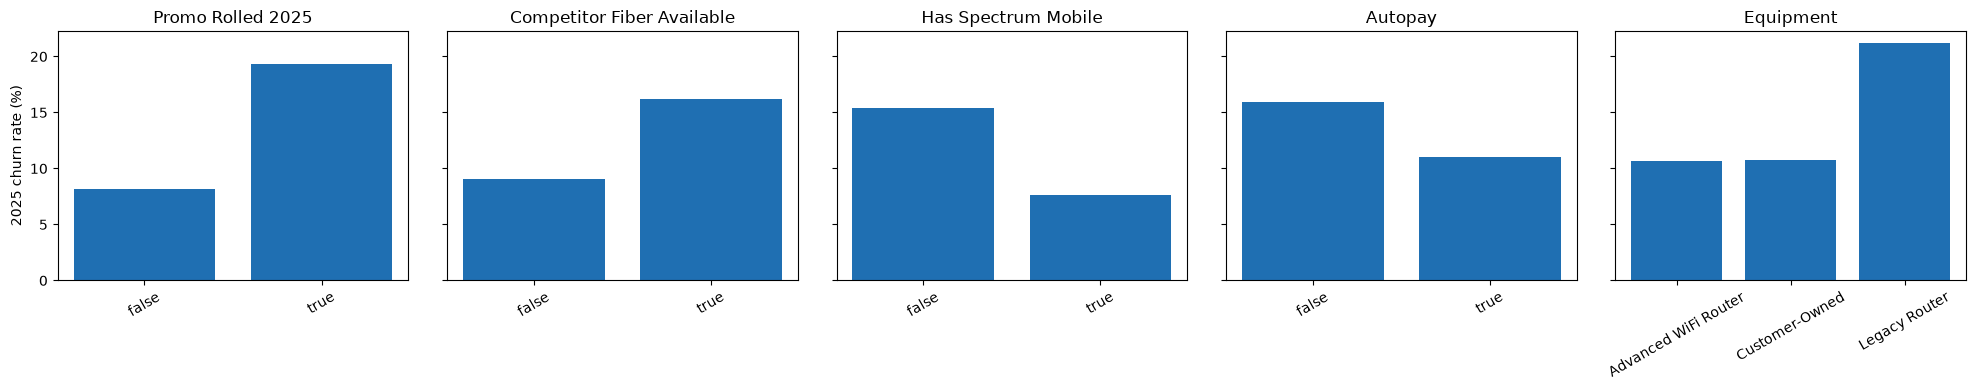

In [4]:
drivers = ["promo_rolled_2025", "competitor_fiber_available",
           "has_spectrum_mobile", "autopay", "equipment"]
fig, axes = plt.subplots(1, len(drivers), figsize=(20, 4), sharey=True)
for ax, col in zip(axes, drivers):
    df = q(f"""SELECT CAST({col} AS VARCHAR) AS grp,
                      100.0 * AVG(CASE WHEN churned THEN 1 ELSE 0 END) AS churn_pct
               FROM customers_clean GROUP BY 1 ORDER BY 1""")
    ax.bar(df.grp, df.churn_pct, color="#1f6fb2")
    ax.set_title(col.replace("_", " ").title())
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("2025 churn rate (%)")
plt.tight_layout()
plt.savefig("../images/churn_drivers.png", dpi=150)
plt.show()



In [5]:
q("""SELECT churn_reason, COUNT(*) AS customers,
            ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct
     FROM customers_clean WHERE churned
     GROUP BY 1 ORDER BY 2 DESC""")


,churn_reason,customers,pct
0,Price increase after promo,1030,38.9
1,Switched to competitor,608,23.0
2,Service reliability,294,11.1
3,Moved out of footprint,283,10.7
4,Slow speeds,160,6.0
5,Customer service experience,156,5.9
6,Other,118,4.5


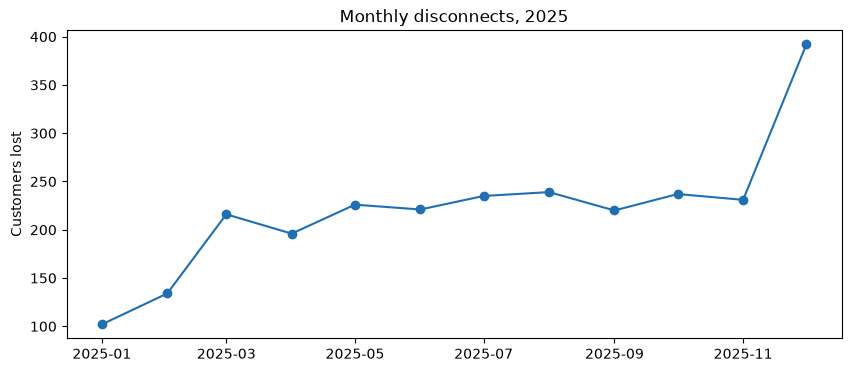

In [6]:
trend = q("""SELECT DATE_TRUNC('month', churn_date) AS month, COUNT(*) AS disconnects
             FROM customers_clean WHERE churned GROUP BY 1 ORDER BY 1""")
plt.figure(figsize=(10, 4))
plt.plot(trend.month, trend.disconnects, marker="o", color="#1f6fb2")
plt.title("Monthly disconnects, 2025")
plt.ylabel("Customers lost")
plt.savefig("../images/monthly_churn.png", dpi=150)
plt.show()

In [8]:
con.close()
